# 第094讲可执行实验

先阅读lecture.md与lab.md，再重启内核从上到下执行。所有数据本地合成；不调用网络、GPU或付费模型。输出会覆盖本讲可再生的outputs/figures；探索实验请复制目录。

## 1 核对环境与工作目录
Notebook依赖同目录experiment.py。不要只下载.ipynb。

In [1]:
from pathlib import Path
import sys, json
import numpy as np
ROOT = Path.cwd()
assert (ROOT / "experiment.py").exists(), "请切换到本讲目录"
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)

Python: 3.12.14 NumPy: 2.3.5


## 2 阅读实现并形成预测
下面列出核心实验源码。先对照讲义找出数据生成、模型或解析场、积分与评价四个位置。代码内注释解释形状、方向与边界。

In [2]:
import inspect
import experiment
print(inspect.getsource(experiment))

"""DL094: analytic Gaussian VE diffusion, reverse SDE and probability-flow ODE.
Oracle-score numerical laboratory, not trained generative modeling.
"""
from pathlib import Path
import os
os.environ.setdefault('MPLCONFIGDIR','/tmp/dl094-mpl')
import json
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
ROOT=Path(__file__).resolve().parent
V0=.5
BETA=2.
T=1.
MU=.7

def variance(t): return V0+BETA*np.asarray(t)
def score(x,t): return -(x-MU)/variance(t)

def reverse(initial,steps,kind,rng=None,paths=False):
    """Use u=T-t, hence dt=-du. Euler-Maruyama or explicit Euler.
    kind=sde: +beta*score*du + sqrt(beta*du)*z.
    kind=ode: +beta/2*score*du. Fresh independent z at each step.
    """
    if kind not in ('sde','ode'): raise ValueError('kind must be sde or ode')
    if steps < 1: raise ValueError('steps must be positive')
    x=np.asarray(initial).copy();h=T/steps;history=[x[:8].copy()]
    for k in range(steps):
        t=T-k*h
        x +=

## 3 从头重新运行实验
这会真实生成样本、计算指标并重建图形；不是展示缓存结果。

In [3]:
results = experiment.main()

{
  "n": 40000,
  "mean": 0.7,
  "v0": 0.5,
  "beta": 2.0,
  "T": 1.0,
  "description": "oracle score, exact terminal initialization, Euler numerical study",
  "forward_final_variance": 2.477165682900608,
  "forward_theory_final_variance": 2.5,
  "initial_sample_variance": 2.484392495849357,
  "ode_200_rmse_to_exact_map": 0.001411173842749859,
  "results": [
    {
      "method": "sde",
      "steps": 10,
      "h": 0.1,
      "sample_mean": 0.6947173376303732,
      "sample_variance": 0.6043272431373616,
      "discrete_theory_variance": 0.6088406643733204,
      "theory_variance_abs_error": 0.1088406643733204,
      "ks_to_target": 0.024525215122861765
    },
    {
      "method": "sde",
      "steps": 20,
      "h": 0.05,
      "sample_mean": 0.6979093835167639,
      "sample_variance": 0.5513526851861192,
      "discrete_theory_variance": 0.5512807311997243,
      "theory_variance_abs_error": 0.051280731199724316,
      "ks_to_target": 0.01546659377572851
    },
    {
      "method

## 4 核对持久化证据
先看每个数组的形状与是否有限，再解释指标。

In [4]:
saved = json.loads((ROOT / "outputs/metrics.json").read_text())
print(json.dumps(saved, ensure_ascii=False, indent=2))
with np.load(ROOT / "outputs/data.npz") as data:
    for key in data.files:
        a = data[key]
        print(key, a.shape, "finite:", bool(np.isfinite(a).all()))

{
  "n": 40000,
  "mean": 0.7,
  "v0": 0.5,
  "beta": 2.0,
  "T": 1.0,
  "description": "oracle score, exact terminal initialization, Euler numerical study",
  "forward_final_variance": 2.477165682900608,
  "forward_theory_final_variance": 2.5,
  "initial_sample_variance": 2.484392495849357,
  "ode_200_rmse_to_exact_map": 0.001411173842749859,
  "results": [
    {
      "method": "sde",
      "steps": 10,
      "h": 0.1,
      "sample_mean": 0.6947173376303732,
      "sample_variance": 0.6043272431373616,
      "discrete_theory_variance": 0.6088406643733204,
      "theory_variance_abs_error": 0.1088406643733204,
      "ks_to_target": 0.024525215122861765
    },
    {
      "method": "sde",
      "steps": 20,
      "h": 0.05,
      "sample_mean": 0.6979093835167639,
      "sample_variance": 0.5513526851861192,
      "discrete_theory_variance": 0.5512807311997243,
      "theory_variance_abs_error": 0.051280731199724316,
      "ks_to_target": 0.01546659377572851
    },
    {
      "method

## 5 看完整图，不挑漂亮样本
图与讲义对应。观察不符合直觉的地方，结合指标解释。

01_paths.png


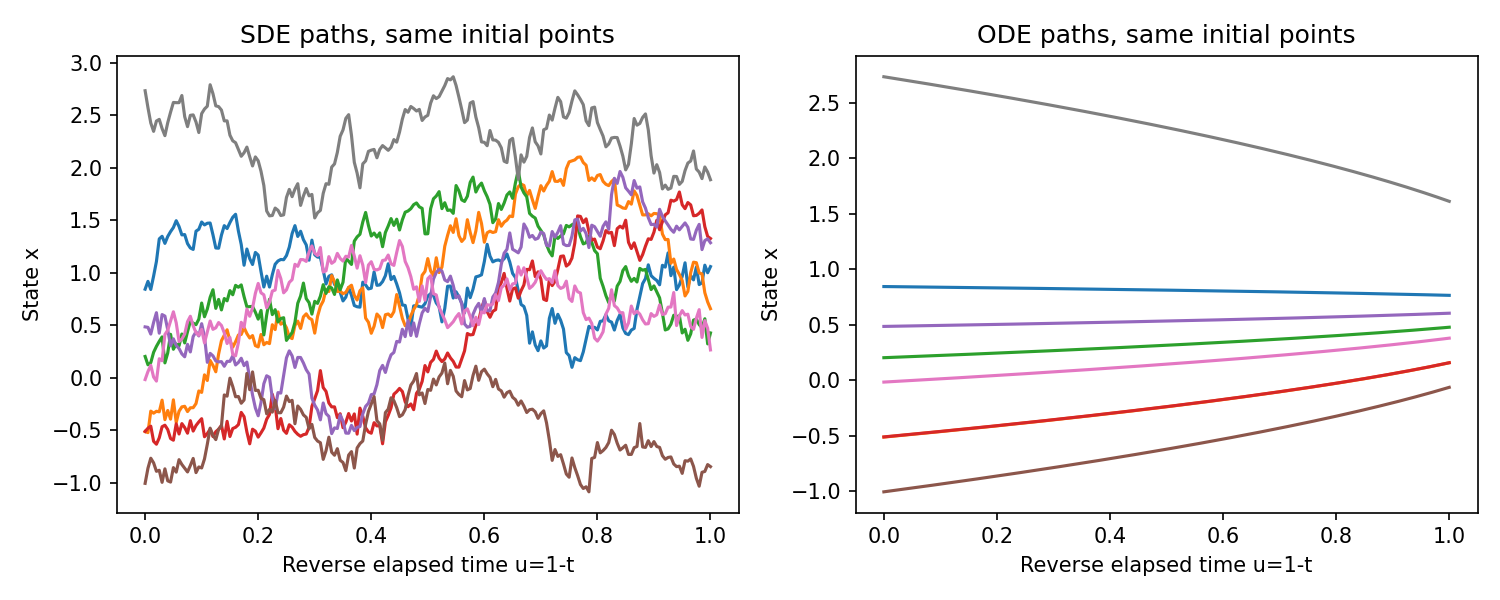

02_marginals.png


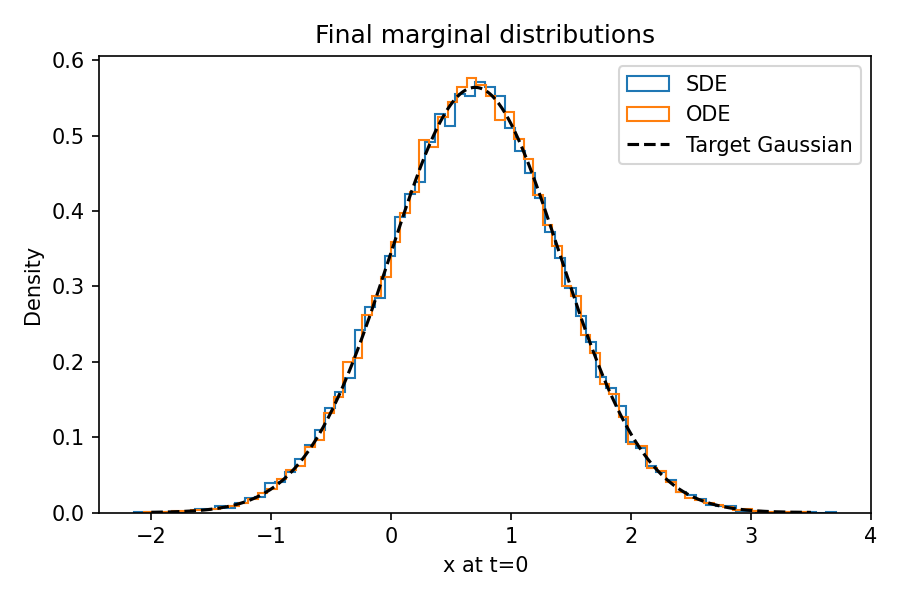

03_step_error.png


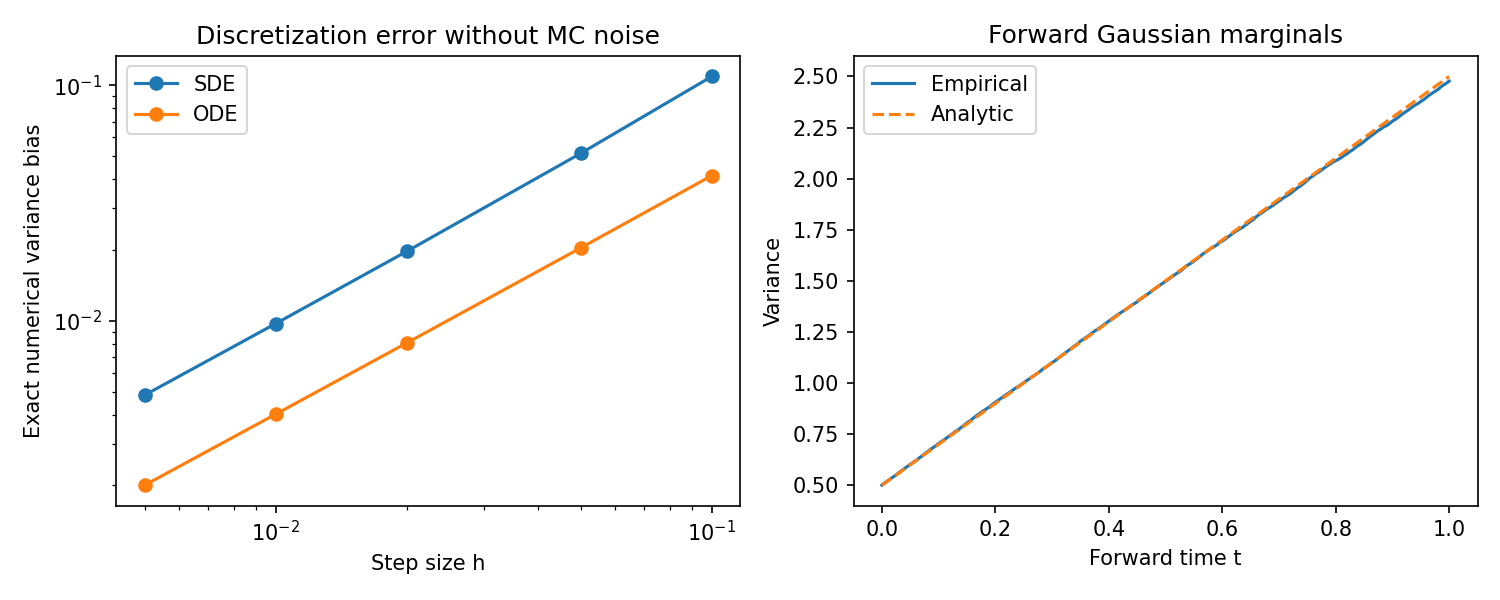

In [5]:
from IPython.display import display, Image
for figure in sorted((ROOT / "figures").glob("*.png")):
    print(figure.name)
    display(Image(filename=str(figure), width=760))

## 6 执行独立断言
测试通过只覆盖这些明确断言，不等于现实部署验证。之后按lab.md做一个受控变化。

In [6]:
import unittest
import tests
suite = unittest.defaultTestLoader.loadTestsFromModule(tests)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()

test_ode_convergence (tests.DiffusionTests.test_ode_convergence) ... 

ok


test_one_step_recurrence (tests.DiffusionTests.test_one_step_recurrence) ... 

ok


test_saved_distribution (tests.DiffusionTests.test_saved_distribution) ... 

...

test_score (tests.DiffusionTests.test_score) ... 

ok


test_variance_convergence (tests.DiffusionTests.test_variance_convergence) ... 

ok


----------------------------------------------------------------------
Ran 5 tests in 0.009s

OK


## 反思与交付
写清本实验是学习模型还是解析score、样本数和种子、主要误差来源、实际结果与未检验范围。练习详解见answers.md。